## Evaluation

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 07.07.2025
- Date of Last Modification: 07.07.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

In [381]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [384]:
import os

import numpy as np
import pandas as pd
import scanpy as sc
from datasets import load_from_disk
from sklearn.model_selection import train_test_split

from app.infer import (embed_dataset,
                       harmonize_adata,
                       tokenize_adata,
                       perturb_dataset,
                       harmonize_tokenize_embed_pipeline,
                       get_average_gene_embed)
from nichejepa.evaluation import (get_adata_cellphonedb_lr_pairs,
                                  get_adata_omnipath_lr_pairs,
                                  knn_classifier,
                                  linear_classifier,
                                  linear_regressor)

In [280]:
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
model_timestamp = '11062025_183320_055'
model_folder_path = f'{artifacts_folder_path}/models/{model_timestamp}'

In [5]:
dataset_name = 'xhk1007-CV1-41b_1p'
cell_type_key = 'level_1_cell_type'
file_path = f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/CV1-KID-0-FT-2.h5ad'

## xhs1000-39b_1p (Xenium Human Skin Eczema)

In [279]:
dataset_name = 'xhs1000-39b_1p'
cell_type_key = 'annotation_new7'
niche_key = 'NICHE_NAMES'
file_paths = [
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/adata_batch11.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/adata_batch19.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/adata_batch32.h5ad']

In [324]:
seed = 0

In [288]:
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None

In [287]:
adata_list = []
dataset_list = []
output_embed_list = []

for file_path in file_paths:
    # Load AnnData
    adata = sc.read_h5ad(file_path)

    # Harmonize AnnData
    adata = harmonize_adata(adata)
    adata_list.append(adata)

    # Tokenize AnnData
    dataset = tokenize_adata(
        adata,
        model_folder_path,
        nproc = 4,
        processing_mode = 'parallel')

    # Save tokenized data
    num_shards = 32
    save_dataset_path = f'{artifacts_folder_path}/{dataset_name}/{file_path.split("/")[-1].split(".")[0]}.dataset'
    os.makedirs(f'{artifacts_folder_path}/{dataset_name}', exist_ok=True)
    dataset.save_to_disk(
        save_dataset_path,
        num_shards=num_shards)
    dataset_list.append(dataset)

    # Retrieve cell and neighborhood embeddings
    output_embed = embed_dataset(
        dataset=dataset,
        model_folder_path=model_folder_path,
        emb_layer=emb_layer,
        agg_excluded_tokens=agg_excluded_tokens,
        top_k=top_k,
        batch_size=batch_size,
        pin_memory=pin_memory,
        num_workers=num_workers)
    output_embed_list.append(output_embed)

STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle
INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055/token_dictionary.pkl.


Number of genes with matching ensembl IDs:           4948.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:654: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using dictionary for dataset creation.
INFO:nichejepa.tokenizers.cell_tokenizers:Formatting gene tokens...
Saving the dataset (32/32 shards): 100%|██████████| 17832/17832 [00:11<00:00, 1601.99 examples/s]


... (8 outputs left out)

Number of genes with matching ensembl IDs:           4948.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:654: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using dictionary for dataset creation.
INFO:nichejepa.tokenizers.cell_tokenizers:Formatting gene tokens...
Saving the dataset (32/32 shards): 100%|██████████| 18439/18439 [00:11<00:00, 1631.05 examples/s]


In [301]:
# Concatenate AnnData objects of all samples/batches
adata = sc.concat(adata_list, axis=0)

# Retrieve cell and neighborhood embeddings for all samples/batches
cell_emb = np.concatenate([output_embed['cell_emb'] for output_embed in output_embed_list], axis=0)
neighborhood_emb = np.concatenate([output_embed['neighborhood_emb'] for output_embed in output_embed_list], axis=0)

# Add embeddings to AnnData object
adata.obsm['cell_emb'] = cell_emb
adata.obsm['neighborhood_emb'] = neighborhood_emb

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


### Train Niche Transfer Classifier

In [341]:
# Filter cells with missing labels
adata_filtered = adata[~adata.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

In [342]:
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm['neighborhood_emb']

In [347]:
# Get train and validation indices
train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
train_val_labels = niche_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    stratify=train_val_labels
)

# Get test indices
test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_val = niche_features[val_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_val = niche_labels[val_indices]
niche_labels_test = niche_labels[test_indices]

In [352]:
# Train and evaluate linear niche transfer classifier
# 0.891 accuracy
pred_niche_labels_test, _, _, model = linear_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_val=niche_features_val,
    labels_val=niche_labels_val,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(niche_categories[pred_niche_labels_test])

Using device: cuda
Epoch 1: Train Loss = 217.5594, Val Loss = 0.4738
Epoch 2: Train Loss = 101.7226, Val Loss = 0.3699
Epoch 3: Train Loss = 85.5124, Val Loss = 0.3328
Epoch 4: Train Loss = 78.0343, Val Loss = 0.3124
Epoch 5: Train Loss = 73.6782, Val Loss = 0.2997
Epoch 6: Train Loss = 71.0410, Val Loss = 0.2906
Epoch 7: Train Loss = 69.0421, Val Loss = 0.2835
Epoch 8: Train Loss = 67.1029, Val Loss = 0.2784
Epoch 9: Train Loss = 65.6287, Val Loss = 0.2736
Epoch 10: Train Loss = 64.5817, Val Loss = 0.2697
Epoch 11: Train Loss = 63.6492, Val Loss = 0.2665
Epoch 12: Train Loss = 63.1062, Val Loss = 0.2634
Epoch 13: Train Loss = 62.0703, Val Loss = 0.2618
Epoch 14: Train Loss = 61.6238, Val Loss = 0.2592
Epoch 15: Train Loss = 61.5035, Val Loss = 0.2570
Epoch 16: Train Loss = 60.3527, Val Loss = 0.2548
Epoch 17: Train Loss = 60.0810, Val Loss = 0.2535
Epoch 18: Train Loss = 59.3881, Val Loss = 0.2513
Epoch 19: Train Loss = 59.1015, Val Loss = 0.2503
Epoch 20: Train Loss = 58.7357, Val Lo

In [379]:
adata_test = adata_list[1]
adata_test.obs[f'{niche_key}_pred'] = niche_categories[pred_niche_labels_test]

In [373]:
# Define custom palette
custom_palette = {
    'KC': '#E41A1C',                              # red
    'KC_T2_LC': '#377EB8',                        # blue
    'Basal epidermis/superficial dermis': '#4DAF4A',  # green
    'Interstitial stroma': '#984EA3',             # purple
    'Perivascular depeer': '#FF7F00',             # orange
    'Schwann_KC_HF': '#A65628',                   # brown
    'Perivascular superficial': '#F781BF',        # pink
    'Sweat gland2': '#999999',                    # gray
    'Sweat gland1': '#66C2A5',                    # teal
    'Muscle': '#FFD92F',                          # yellow
    'Sebocyte': '#A6D854',                        # lime
    'Epidermis with T2': '#E78AC3'                # rose
}

/tmp/ipykernel_1364979/3230781588.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


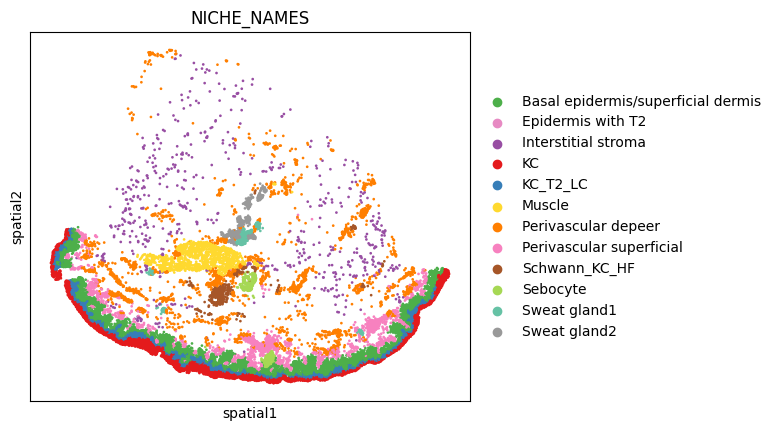

In [375]:
# Visualize ground truth niche labels in training samples
sc.pl.spatial(
    adata_list[0],
    color=niche_key,
    palette=custom_palette,
    spot_size=30)   

/tmp/ipykernel_1364979/3291664540.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


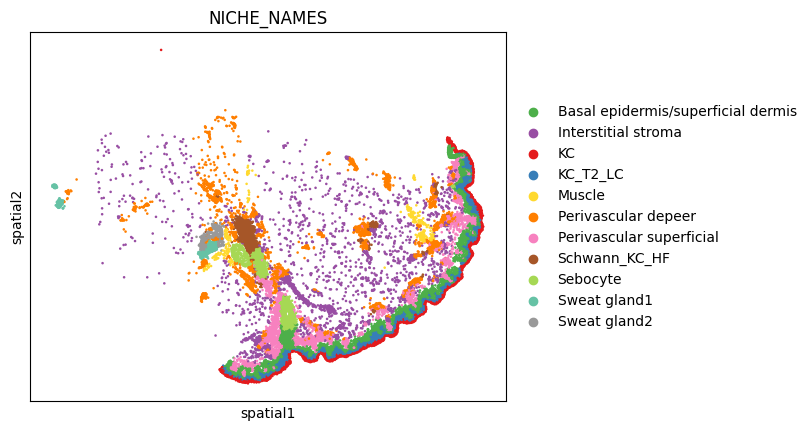

In [376]:
sc.pl.spatial(
    adata_list[2],
    color=niche_key,
    palette=custom_palette,
    spot_size=30)   

/tmp/ipykernel_1364979/3233442671.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


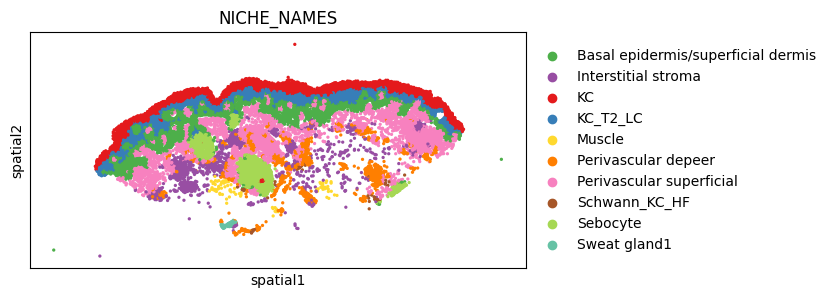

In [377]:
# Visualize ground truth niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=niche_key,
    palette=custom_palette,
    spot_size=30)   

/tmp/ipykernel_1364979/718215267.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'NICHE_NAMES_pred' as categorical


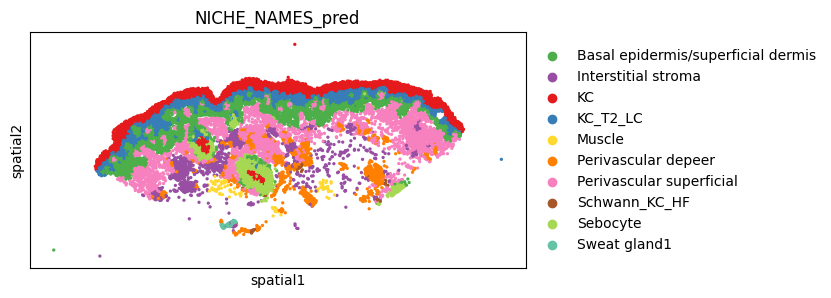

In [380]:
# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred',
    palette=custom_palette,
    spot_size=30)   

In [383]:
# Get train and test indices
train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [385]:
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test)

adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

Using device: cuda

--- Evaluation Report on Test Set ---
              precision    recall  f1-score   support

           0     0.7999    0.9382    0.8635      3865
           1     0.8802    0.7502    0.8100      1185
           2     0.8443    0.9373    0.8884      2008
           3     0.7587    0.7673    0.7630      2578
           4     0.8947    0.9770    0.9341        87
           5     0.6992    0.7789    0.7369      1298
           6     0.9102    0.9009    0.9055      4421
           7     0.5273    0.5088    0.5179        57
           8     0.8727    0.4668    0.6082      1821
           9     0.9661    0.8906    0.9268        64

    accuracy                         0.8278     17384
   macro avg     0.8153    0.7916    0.7954     17384
weighted avg     0.8327    0.8278    0.8218     17384



/tmp/ipykernel_1364979/2053663697.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'NICHE_NAMES_pred_knn' as categorical


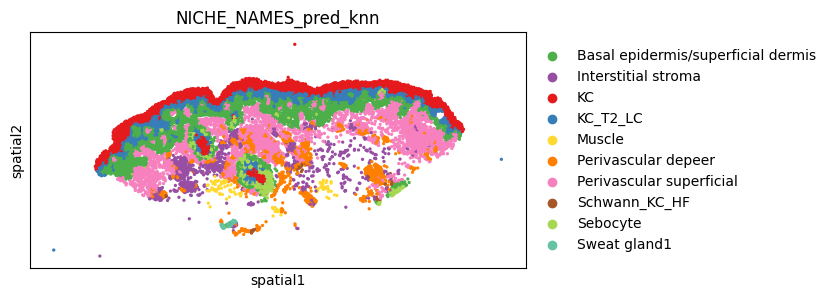

In [386]:
# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=custom_palette,
    spot_size=30)   

### Train Cell Type Transfer Classifier

In [396]:
custom_palette = {
    'KC4-5': '#1f78b4',
    'KC3': '#33a02c',
    'KC1': '#fb9a99',
    'Melanocyte': '#e31a1c',
    'KC2': '#a6cee3',
    'F2: Universal': '#fdbf6f',
    'Mac': '#b2df8a',
    'cDC2': '#cab2d6',
    'T': '#6a3d9a',
    'F3: TRC-like': '#ff7f00',
    'F2/3: Bridge': '#b15928',
    'T_GZMK+': '#ffff99',
    'F1: Superficial': '#8dd3c7',
    'VE/Pericyte': '#ffffb3',
    'cDC1': '#bebada',
    'LE': '#fb8072',
    'F5: Schwann-like': '#80b1d3',
    'Sweat gland channel outer': '#fdb462',
    'Sweat gland': '#b3de69',
    'F4: Mixed': '#fccde5',
    'Treg': '#d9d9d9',
    'Nonspecific': '#bc80bd',
    'Pre-adipocyte PPARG+ANGPTL8': '#ccebc5',
    'MigDC': '#ffed6f',
    'LC': '#a1dab4',
    'T_ITGAEhi_IL22': '#41b6c4',
    'T_vascular': '#2c7fb8',
    'Mast cell': '#253494',
    'Muscle': '#fed976',
    'KC_HF_Basal': '#e31a1c',
    'KC_HF_ORS': '#bd0026',
    'Sebocyte_CCL19': '#54278f',
    'Schwann': '#756bb1',
    'Sebocyte_PPARG': '#9e9ac8',
    'ILC2/Tnaive': '#6baed6',
    'F4: TNN+COCH+': '#4292c6',
    'pDC': '#2171b5',
    'KC_HF_inner': '#08519c',
    'LC/MigDC': '#08306b',
    'Plasma cell': '#ff66a1'
}

/tmp/ipykernel_1364979/1255094889.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


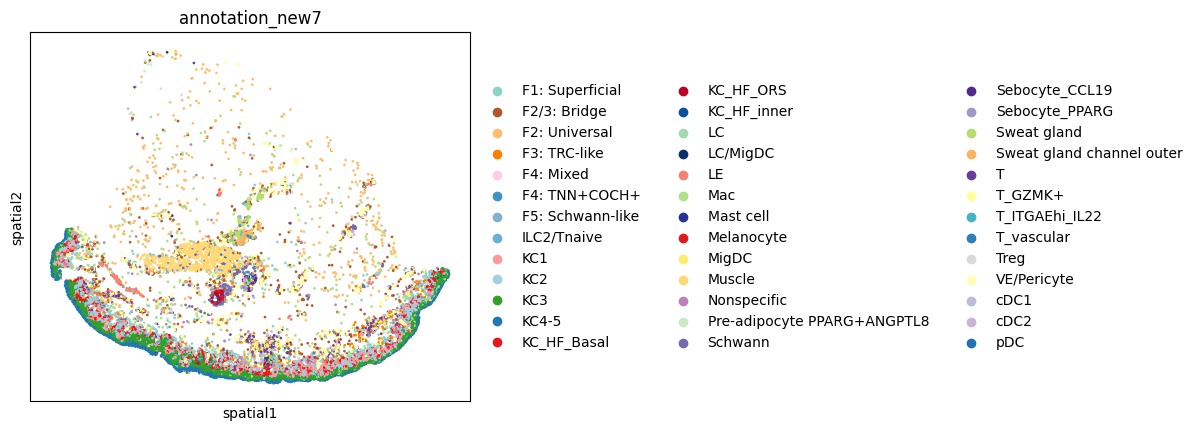

In [393]:
# Visualize ground truth cell type labels in training samples
sc.pl.spatial(
    adata_list[0],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=30)   

/tmp/ipykernel_1364979/3804811254.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


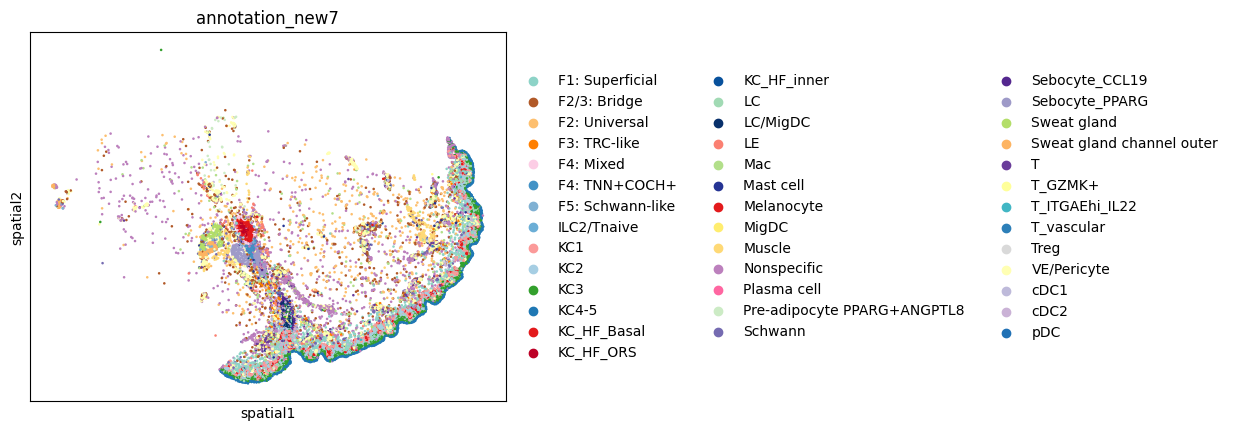

In [397]:
sc.pl.spatial(
    adata_list[2],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=30)   

/tmp/ipykernel_1364979/4070255450.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


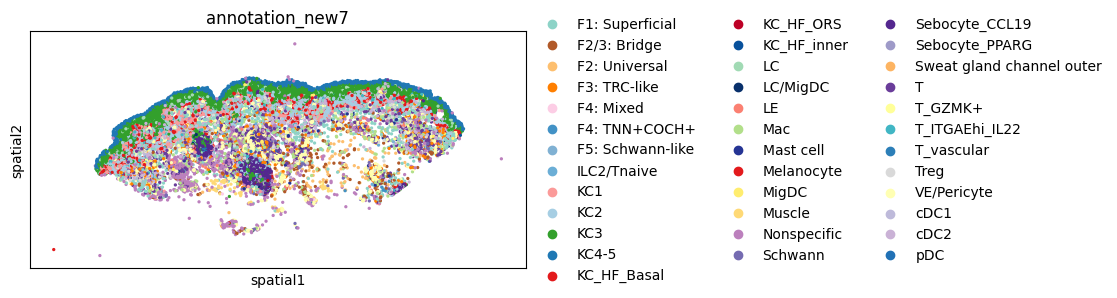

In [398]:
sc.pl.spatial(
    adata_list[1],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=30)   

In [388]:
# Filter cells with missing labels
adata_filtered = adata[~adata.obs[cell_type_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[cell_type_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[cell_type_key].isin(valid_cats)]

cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
cell_type_features = adata_filtered.obsm['cell_emb']

# Get train and validation indices
train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
train_val_labels = cell_type_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    stratify=train_val_labels
)

# Get test indices
test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_val = cell_type_features[val_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_val = cell_type_labels[val_indices]
cell_type_labels_test = cell_type_labels[test_indices]

In [399]:
# Train and evaluate linear niche transfer classifier
# 0.891 accuracy
pred_cell_type_labels_test, _, _, model = linear_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_val=cell_type_features_val,
    labels_val=cell_type_labels_val,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(cell_type_categories[pred_cell_type_labels_test])

Using device: cuda
Epoch 1: Train Loss = 503.7296, Val Loss = 1.3711
Epoch 2: Train Loss = 312.2446, Val Loss = 1.1132
Epoch 3: Train Loss = 270.2238, Val Loss = 1.0029
Epoch 4: Train Loss = 247.8351, Val Loss = 0.9368
Epoch 5: Train Loss = 234.3217, Val Loss = 0.8922
Epoch 6: Train Loss = 225.9358, Val Loss = 0.8597
Epoch 7: Train Loss = 218.6944, Val Loss = 0.8340
Epoch 8: Train Loss = 212.6437, Val Loss = 0.8141
Epoch 9: Train Loss = 206.8041, Val Loss = 0.7978
Epoch 10: Train Loss = 202.0558, Val Loss = 0.7831
Epoch 11: Train Loss = 198.9064, Val Loss = 0.7716
Epoch 12: Train Loss = 196.4221, Val Loss = 0.7612
Epoch 13: Train Loss = 193.2028, Val Loss = 0.7514
Epoch 14: Train Loss = 190.5851, Val Loss = 0.7433
Epoch 15: Train Loss = 188.1884, Val Loss = 0.7362
Epoch 16: Train Loss = 187.8872, Val Loss = 0.7297
Epoch 17: Train Loss = 185.7956, Val Loss = 0.7236
Epoch 18: Train Loss = 183.2658, Val Loss = 0.7182
Epoch 19: Train Loss = 181.7985, Val Loss = 0.7133
Epoch 20: Train Loss 

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metr

In [400]:
adata_test.obs[f'{cell_type_key}_pred'] = cell_type_categories[pred_cell_type_labels_test]

/tmp/ipykernel_1364979/2485538307.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'annotation_new7_pred' as categorical


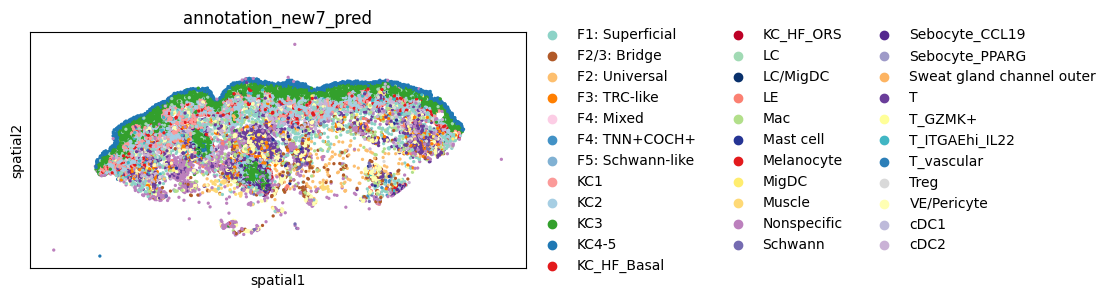

In [401]:
sc.pl.spatial(
    adata_list[1],
    color=f'{cell_type_key}_pred',
    palette=custom_palette,
    spot_size=30)   

Using device: cuda


/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capit


--- Evaluation Report on Test Set ---
              precision    recall  f1-score   support

           0     0.6857    0.8455    0.7573       725
           1     0.4685    0.4190    0.4424       284
           2     0.5266    0.7226    0.6092       137
           3     0.6178    0.6699    0.6428       509
           4     1.0000    0.0714    0.1333        14
           5     0.6667    0.2500    0.3636         8
           6     0.0000    0.0000    0.0000         8
           7     0.0000    0.0000    0.0000        75
           8     0.6080    0.7810    0.6837      1388
           9     0.6182    0.7582    0.6811      2039
          10     0.7130    0.8658    0.7820      2608
          11     0.8748    0.8982    0.8864       786
          12     0.0208    0.2500    0.0385         4
          13     0.0357    0.0909    0.0513        11
          14     0.0000    0.0000    0.0000         1
          15     0.4516    0.3439    0.3904       285
          16     0.0213    0.0667    0.032

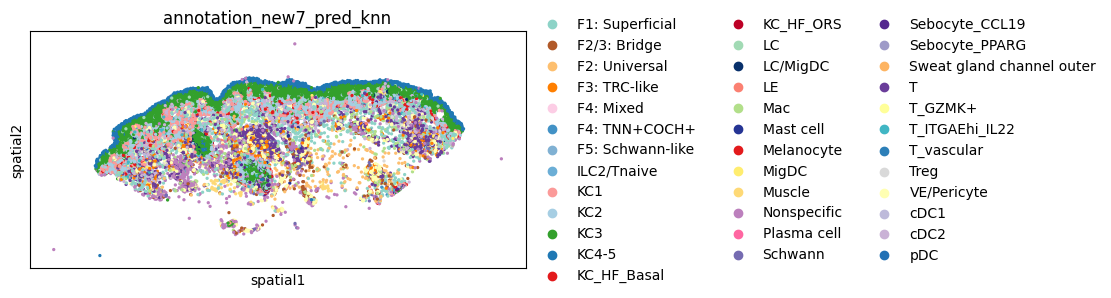

In [402]:
# Get train and test indices
train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_test = cell_type_labels[test_indices]

pred_cell_type_labels_test_knn = knn_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test)

adata_test.obs[f'{cell_type_key}_pred_knn'] = cell_type_categories[pred_cell_type_labels_test_knn]

# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_knn',
    palette=custom_palette,
    spot_size=30)   

### Train Neighborhood Composition Transfer Classifier

In [409]:
adata_list[0]

AnnData object with n_obs × n_vars = 17832 × 4948
    obs: 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'sample_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'leiden_res0.5', 'leiden_res1', 'total_counts_binary', 'total_counts_binary2', 'n_genes_by_counts_binary2', 'xenium_id', 'xenium_id_recoded', 'GSTT patient ID', 'Sanger patient ID', 'Drug', 'Responder', 'Timepoint', "Library type (CITE or 5'GEX/TCR)", 'Segmentation Y/N?', 'Sample ID', 'Xenium slide number', 'Xenium region number2', 'baseline_postrx', 'Site_status', 'info_id', 'annotation', 'run', 'DonorID', 'new_annotation', 'annotation_ne

In [410]:
import scipy.sparse as sp

blocks = [a.obsp['spatial_connectivities'] for a in adata_list]
combined_graph = sp.block_diag(blocks)

adata.obsp['spatial_connectivities'] = combined_graph

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/storage.py:48: FutureWarning: AnnData previously had undefined behavior around matrices of type <class 'scipy.sparse._coo.coo_matrix'>.In 0.12, passing in this type will throw an error. Please convert to a supported type.Continue using for this minor version at your own risk.
  warnings.warn(msg, FutureWarning)


In [403]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

def compute_neighborhood_composition(adata, cell_type_key='cell_type'):
    # Extract required data
    connectivities = adata.obsp['spatial_connectivities']  # shape: (n_cells, n_cells)
    cell_types = adata.obs[cell_type_key].astype('category')  # ensure categorical
    cell_type_names = cell_types.cat.categories
    n_cell_types = len(cell_type_names)

    # One-hot encode the cell types
    one_hot = pd.get_dummies(cell_types).values  # shape: (n_cells, n_cell_types)

    # Convert to sparse for efficiency if needed
    if not isinstance(connectivities, csr_matrix):
        connectivities = csr_matrix(connectivities)

    # Compute neighborhood composition: (n_cells x n_cells) · (n_cells x n_cell_types)
    # Result: (n_cells x n_cell_types) where each row is a vector of neighbor cell type counts
    neighborhood_counts = connectivities.dot(one_hot)

    # Optionally normalize to get proportions
    neighborhood_sums = neighborhood_counts.sum(axis=1, keepdims=True)
    neighborhood_proportions = neighborhood_counts / (neighborhood_sums + 1e-10)

    # Wrap in DataFrame for interpretability
    composition_df = pd.DataFrame(neighborhood_proportions, columns=cell_type_names, index=adata.obs_names)

    return composition_df

In [411]:
composition_df = compute_neighborhood_composition(adata, cell_type_key)

In [413]:
cell_type_composition_labels

array([[0. , 0. , 0. , ..., 0. , 0. , 0. ],
       [0. , 0. , 0. , ..., 0. , 0. , 0. ],
       [0. , 0. , 0. , ..., 0. , 0. , 0. ],
       ...,
       [0.6, 0. , 0. , ..., 0. , 0.1, 0. ],
       [0.8, 0. , 0. , ..., 0. , 0.1, 0. ],
       [0. , 0.1, 0.2, ..., 0. , 0. , 0. ]], shape=(53655, 40))

In [414]:
train_val_labels

array([[0. , 0. , 0. , ..., 0. , 0. , 0. ],
       [0. , 0. , 0. , ..., 0. , 0. , 0. ],
       [0. , 0. , 0. , ..., 0. , 0. , 0. ],
       ...,
       [0.6, 0. , 0. , ..., 0. , 0.1, 0. ],
       [0.8, 0. , 0. , ..., 0. , 0.1, 0. ],
       [0. , 0.1, 0.2, ..., 0. , 0. , 0. ]], shape=(36271, 40))

In [418]:
niche_features_train

array([[ 0.6746918 , -0.21727318,  0.7017563 , ..., -0.09358808,
        -1.393424  ,  0.68369305],
       [ 1.1761754 , -0.32006526,  0.68399733, ..., -0.6093618 ,
        -0.9592609 ,  0.6612944 ],
       [-1.1187177 , -0.29235876, -0.94451517, ...,  0.4483054 ,
        -0.52559525, -0.74622977],
       ...,
       [-0.17307311, -0.7895949 ,  0.49460858, ..., -0.15022826,
        -0.3810404 , -0.44381803],
       [ 0.46109536, -0.39418396,  0.21797092, ...,  0.1549475 ,
        -1.763413  , -0.7501921 ],
       [-0.26628008, -0.5874458 , -0.1639584 , ..., -0.8705605 ,
        -0.1540514 ,  0.40571392]], shape=(32643, 384), dtype=float32)

In [422]:
cell_type_composition_labels = composition_df.values
niche_features = adata.obsm['neighborhood_emb']

# Get train and validation indices
train_val_indices = (adata.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
train_val_labels = cell_type_composition_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    #stratify=train_val_labels
)

# Get test indices
test_indices = (adata.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_val = niche_features[val_indices]
niche_features_test = niche_features[test_indices]
cell_type_composition_labels_train = cell_type_composition_labels[train_indices]
cell_type_composition_labels_val = cell_type_composition_labels[val_indices]
cell_type_composition_labels_test = cell_type_composition_labels[test_indices]

pred_cell_type_composition_labels, model = linear_regressor(
    features_train=niche_features_train,
    labels_train=cell_type_composition_labels_train,
    features_val=niche_features_val,
    labels_val=cell_type_composition_labels_val,
    features_test=niche_features_test,
    labels_test=cell_type_composition_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(pred_cell_type_composition_labels)

Using device: cuda
Epoch 1: Train Loss = 4.1317, Val Loss = 0.0103
Epoch 2: Train Loss = 2.1768, Val Loss = 0.0075
Epoch 3: Train Loss = 1.7181, Val Loss = 0.0063
Epoch 4: Train Loss = 1.4757, Val Loss = 0.0056
Epoch 5: Train Loss = 1.3336, Val Loss = 0.0051
Epoch 6: Train Loss = 1.2342, Val Loss = 0.0048
Epoch 7: Train Loss = 1.1645, Val Loss = 0.0045
Epoch 8: Train Loss = 1.1085, Val Loss = 0.0043
Epoch 9: Train Loss = 1.0659, Val Loss = 0.0042
Epoch 10: Train Loss = 1.0304, Val Loss = 0.0041
Epoch 11: Train Loss = 1.0007, Val Loss = 0.0040
Epoch 12: Train Loss = 0.9747, Val Loss = 0.0039
Epoch 13: Train Loss = 0.9533, Val Loss = 0.0038
Epoch 14: Train Loss = 0.9355, Val Loss = 0.0037
Epoch 15: Train Loss = 0.9189, Val Loss = 0.0036
Epoch 16: Train Loss = 0.9010, Val Loss = 0.0036
Epoch 17: Train Loss = 0.8860, Val Loss = 0.0035
Epoch 18: Train Loss = 0.8774, Val Loss = 0.0035
Epoch 19: Train Loss = 0.8638, Val Loss = 0.0034
Epoch 20: Train Loss = 0.8540, Val Loss = 0.0034
Epoch 21: 

### Ligand-Receptor Prediction

In [423]:
lr_database = 'cellphonedb'

In [427]:
adata.var = adata_list[0].var

In [428]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')

Downloaded cellphonedb.zip into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded complex_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded gene_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded interaction_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded protein_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded uniprot_synonyms.tsv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0/sources
Downloaded transcription_factor_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0/sources



In [429]:
lr_interaction_df

,ligand,receptor
2,ENSG00000039068,ENSG00000139187
4,ENSG00000170558,ENSG00000104921
232,ENSG00000090339,ENSG00000005844
237,ENSG00000108622,ENSG00000090659
239,ENSG00000076662,ENSG00000090659
...,...,...
2895,ENSG00000170893,ENSG00000174417
2900,ENSG00000204936,ENSG00000261371
2901,ENSG00000196776,ENSG00000198053
2902,ENSG00000196776,ENSG00000089012


In [430]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()

output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: GETTING AVERAGE GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1441: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
145it [06:42,  2.78s/it]
/nfs/team361/sb75/nichejepa/src/app/infer.py:1704: RuntimeWarning: invalid value encountered in divide
  cell_gene_emb_features.append((sum_emb / count_emb).reshape(1, -1))
/nfs/team361/sb75/nichejepa/src/app/infer.py:1711: RuntimeWarning: invalid value encountered in divide
  neighborhood_gene_emb_features.append((sum_emb / count_emb).reshape(1, -1))


In [432]:
# Filter embeddings with too few occurrences in either neighborhood or cell gene
min_count_threshhold = 10

neighborhood_gene_emb_avg = output_average_gene_embed['neighborhood_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]
cell_gene_emb_avg = output_average_gene_embed['cell_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]

# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

# Use second half og ligand-receptor pairs as negative pairs
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])


(167, 768)
(167, 768)


In [435]:
seed = 0
train_ratio = 0.8
test_ratio = 0.1
val_ratio = 0.1

In [436]:
# --- Splitting using sklearn ---
# First, split off the test set
ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
    ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)

# Then split the remaining temp set into train and val
# The new val ratio is relative to the remaining data
val_relative_ratio = val_ratio / (train_ratio + val_ratio)

ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
    ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)

In [437]:
pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
    features_train=ligand_receptor_features_train,
    labels_train=ligand_receptor_labels_train,
    features_val=ligand_receptor_features_val,
    labels_val=ligand_receptor_labels_val,
    features_test=ligand_receptor_features_test,
    labels_test=ligand_receptor_labels_test,
    n_epochs=400,
    batch_size=16,
    )

Using device: cuda
Epoch 1: Train Loss = 11.7705, Val Loss = 0.6740
Epoch 2: Train Loss = 11.5102, Val Loss = 0.6713
Epoch 3: Train Loss = 11.2987, Val Loss = 0.6857
Epoch 4: Train Loss = 11.0886, Val Loss = 0.6817
Epoch 5: Train Loss = 10.8564, Val Loss = 0.6634
Epoch 6: Train Loss = 10.6940, Val Loss = 0.6503
Epoch 7: Train Loss = 10.5261, Val Loss = 0.6420
Epoch 8: Train Loss = 10.3534, Val Loss = 0.6483
Epoch 9: Train Loss = 10.2167, Val Loss = 0.6267
Epoch 10: Train Loss = 10.0198, Val Loss = 0.6355
Epoch 11: Train Loss = 9.8759, Val Loss = 0.6298
Epoch 12: Train Loss = 9.7360, Val Loss = 0.6132
Epoch 13: Train Loss = 9.5617, Val Loss = 0.6192
Epoch 14: Train Loss = 9.4324, Val Loss = 0.6125
Epoch 15: Train Loss = 9.3207, Val Loss = 0.5983
Epoch 16: Train Loss = 9.1805, Val Loss = 0.5881
Epoch 17: Train Loss = 9.0399, Val Loss = 0.5831
Epoch 18: Train Loss = 8.9413, Val Loss = 0.5850
Epoch 19: Train Loss = 8.9241, Val Loss = 0.5736
Epoch 20: Train Loss = 8.7403, Val Loss = 0.5703


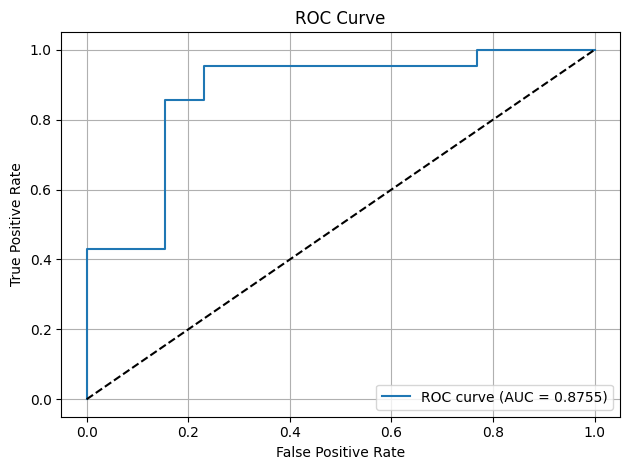

In [438]:
import numpy as np
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from scipy.special import softmax

# Convert to numpy arrays
logits = np.stack(lr_logits)             # shape (N, 2)
labels = np.array(lr_labels)             # shape (N,)

# Apply softmax to get probabilities
probs = softmax(logits, axis=1)       # shape (N, 2)
pos_probs = probs[:, 1]               # probability of class 1

# Compute ROC curve and AUC
fpr, tpr, _ = roc_curve(labels, pos_probs)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure()
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

In [298]:
cell_emb.shape

(53655, 384)

In [ ]:
dataset = tokenize_adata(adata,
                         model_folder_path,
                         nproc = 4,
                         processing_mode = 'parallel')

#item = dataset[0]
#print(item)

In [ ]:
# Save tokenized data
num_shards = 32
save_dataset_path = f'{artifacts_folder_path}/{dataset_name}/{dataset_name}.dataset'
os.makedirs(f'{artifacts_folder_path}/{dataset_name}', exist_ok=True)
dataset.save_to_disk(
    save_dataset_path,
    num_shards=num_shards)

In [7]:
# Load tokenized data
load_dataset_path = f'{artifacts_folder_path}/{dataset_name}/{dataset_name}.dataset'
dataset = load_from_disk(load_dataset_path)

In [270]:
 f'{artifacts_folder_path}/{dataset_name}/{dataset_name}.dataset'

'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/xhk1007-CV1-41b_1p/xhk1007-CV1-41b_1p.dataset'

In [25]:
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None

In [ ]:
output_embed = embed_dataset(
    dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers)

In [ ]:
output_embed['neighborhood_emb'].shape

In [ ]:
# Add embeddings to AnnData object
adata.obsm['neighborhood_emb'] = output_embed['neighborhood_emb']
adata.obsm['cell_emb'] = output_embed['cell_emb']


In [56]:

# Filter cells with missing labels
adata_filtered = adata[~adata.obs[cell_type_key].isna()]

In [57]:
cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
features = adata_filtered.obsm['cell_emb']

KeyError: 'cell_emb'

In [58]:
cell_type_labels

array([3, 1, 1, ..., 1, 1, 1], shape=(71104,), dtype=int8)

In [ ]:
adata.obs[f'{cell_type_key}_predicted'] = cell_type_categories[pred_cell_type_labels]

In [ ]:
pred_cell_type_labels, model = linear_classifier(
    features=features,
    labels=cell_type_labels,
    train_ratio=0.8,
    val_ratio=0.1,
    seed=0,
    n_epochs=400,
    batch_size=128,
    )

print(cell_type_categories[pred_cell_type_labels])

In [ ]:
pred_cell_type_labels = nichejepa.evaluation.knn.knn_classifier(
    features=features,
    labels=cell_type_labels,
    test_ratio=0.1,
    seed=0,
    )

print(cell_type_categories[pred_cell_type_labels])

In [ ]:
split = dataset.train_test_split(test_size=0.2, seed=0)

In [ ]:
train_dataset = split['train']
test_dataset = split['test']

In [ ]:
train_dataset

In [ ]:
test_dataset

In [ ]:
fine_tune(params,
          train_dataset,
          test_dataset,
          save_folder_path=folder_path,
          use_peft=False,
          LOCAL_RANK=LOCAL_RANK,
          WORLD_RANK=WORLD_RANK)

In [ ]:
adata = predict(
    model_folder_path,
    test_dataset)

## CellPhoneDB

In [11]:
from IPython.display import HTML, display
from cellphonedb.utils import db_releases_utils

display(HTML(db_releases_utils.get_remote_database_versions_html()['db_releases_html_table']))

In [12]:
# -- Version of the databse
cpdb_version = 'v5.0.0'

# -- Path where the input files to generate the database are located
os.makedirs(f'{artifacts_folder_path}/cellphonedb', exist_ok=True)
cpdb_target_dir = os.path.join(f'{artifacts_folder_path}/cellphonedb', cpdb_version)

In [13]:
from cellphonedb.utils import db_utils

db_utils.download_database(cpdb_target_dir, cpdb_version)

Downloaded cellphonedb.zip into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded complex_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded gene_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded interaction_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded protein_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded uniprot_synonyms.tsv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0/sources
Downloaded transcription_factor_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0/sources


In [14]:
f'{cpdb_target_dir}/interaction_input.csv'

'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0/interaction_input.csv'

In [15]:
cpdb_target_dir

'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0'

In [16]:
f'{cpdb_target_dir}/interaction_input.csv'

'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0/interaction_input.csv'

In [17]:
interaction_df = pd.read_csv(f'{cpdb_target_dir}/interaction_input.csv')

In [18]:
# Filter to only keep ligand-receptor interactions
interaction_df_filtered = interaction_df[interaction_df['directionality'] == 'Ligand-Receptor']

# Filter out complexes
interaction_df_filtered = interaction_df_filtered[~interaction_df_filtered['interactors'].apply(lambda x: '+' in x)]

interaction_df_filtered['ligand'] = interaction_df_filtered['interactors'].apply(lambda x: x.split('-')[0])
interaction_df_filtered['receptor'] = interaction_df_filtered['interactors'].apply(lambda x: x.split('-')[1])

In [19]:
interaction_df_filtered = interaction_df_filtered[['ligand', 'receptor']]

In [20]:
interaction_df_filtered

,ligand,receptor
2,CDH1,KLRG1
4,CDH2,FCER2
232,ICAM1,ITGAL
237,ICAM2,CD209
239,ICAM3,CD209
...,...,...
2906,NLGN4Y,NRXN3
2907,PVR,KIR2DL5A
2908,SDC2,FGFR4
2909,SEMA4D,PLXNB3


In [21]:
# Map gene names to ensembl IDs
interaction_df_filtered['ligand'] = interaction_df_filtered['ligand'].map(adata.var['ensembl_id'])
interaction_df_filtered['receptor'] = interaction_df_filtered['receptor'].map(adata.var['ensembl_id'])

In [22]:
# Drop interactions where ligand or receptor is not in AnnData object
interaction_df_filtered = interaction_df_filtered.dropna()
interaction_df_filtered

,ligand,receptor
2,ENSG00000039068,ENSG00000139187
4,ENSG00000170558,ENSG00000104921
232,ENSG00000090339,ENSG00000005844
237,ENSG00000108622,ENSG00000090659
239,ENSG00000076662,ENSG00000090659
...,...,...
2895,ENSG00000170893,ENSG00000174417
2900,ENSG00000204936,ENSG00000261371
2901,ENSG00000196776,ENSG00000198053
2902,ENSG00000196776,ENSG00000089012


In [262]:
lr_database = 'omnipath'

In [263]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')

In [213]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()

output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: GETTING AVERAGE GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


556it [47:47,  5.16s/it]


In [216]:
# Filter embeddings with too few occurrences in either neighborhood or cell gene
min_count_threshhold = 10

neighborhood_gene_emb_avg = output_average_gene_embed['neighborhood_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]
cell_gene_emb_avg = output_average_gene_embed['cell_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]

In [269]:
dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_ids', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens'],
    num_rows: 71118
})

In [268]:
np.max(output_average_gene_embed['cell_gene_emb_counts_per_data'
])

np.int64(419874)

In [217]:
# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

In [218]:
# Use second half og ligand-receptor pairs as negative pairs
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)

In [219]:
if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

(538, 768)
(538, 768)


In [220]:
ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

In [221]:
# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])

In [173]:
pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
    features=ligand_receptor_features,
    labels=ligand_receptor_labels,
    train_ratio=0.8,
    val_ratio=0.1,
    seed=0,
    n_epochs=400,
    batch_size=16,
    )

Using device: cuda
Epoch 1: Train Loss = 12.3188, Val Loss = 0.6460
Epoch 2: Train Loss = 12.1662, Val Loss = 0.6397
Epoch 3: Train Loss = 11.9135, Val Loss = 0.6343
Epoch 4: Train Loss = 11.8223, Val Loss = 0.6309
Epoch 5: Train Loss = 11.6616, Val Loss = 0.6281
Epoch 6: Train Loss = 11.4343, Val Loss = 0.6244
Epoch 7: Train Loss = 11.2688, Val Loss = 0.6193
Epoch 8: Train Loss = 11.1712, Val Loss = 0.6146
Epoch 9: Train Loss = 10.9688, Val Loss = 0.6114
Epoch 10: Train Loss = 10.8427, Val Loss = 0.6058
Epoch 11: Train Loss = 10.8675, Val Loss = 0.6033
Epoch 12: Train Loss = 10.5721, Val Loss = 0.6001
Epoch 13: Train Loss = 10.4591, Val Loss = 0.5978
Epoch 14: Train Loss = 10.3104, Val Loss = 0.5920
Epoch 15: Train Loss = 10.2572, Val Loss = 0.5900
Epoch 16: Train Loss = 10.0611, Val Loss = 0.5901
Epoch 17: Train Loss = 10.0433, Val Loss = 0.5876
Epoch 18: Train Loss = 10.0277, Val Loss = 0.5871
Epoch 19: Train Loss = 9.7839, Val Loss = 0.5844
Epoch 20: Train Loss = 9.6147, Val Loss =

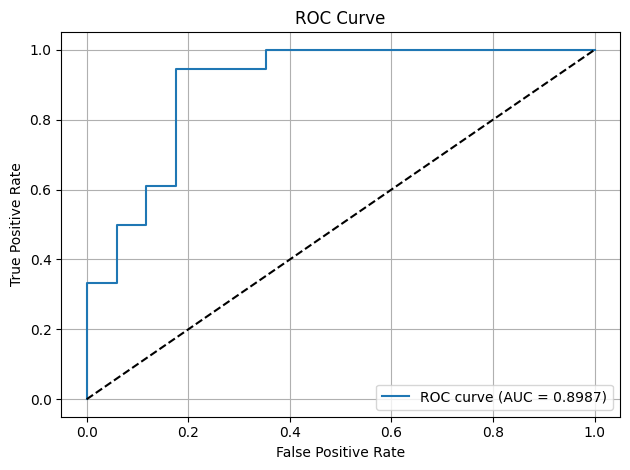

In [174]:
import numpy as np
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from scipy.special import softmax

# Convert to numpy arrays
logits = np.stack(lr_logits)             # shape (N, 2)
labels = np.array(lr_labels)             # shape (N,)

# Apply softmax to get probabilities
probs = softmax(logits, axis=1)       # shape (N, 2)
pos_probs = probs[:, 1]               # probability of class 1

# Compute ROC curve and AUC
fpr, tpr, _ = roc_curve(labels, pos_probs)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure()
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

In [222]:
pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
    features=ligand_receptor_features,
    labels=ligand_receptor_labels,
    train_ratio=0.8,
    val_ratio=0.1,
    seed=0,
    n_epochs=400,
    batch_size=16,
    )

Using device: cuda
Epoch 1: Train Loss = 37.3436, Val Loss = 0.6829
Epoch 2: Train Loss = 36.5910, Val Loss = 0.6724
Epoch 3: Train Loss = 36.0823, Val Loss = 0.6626
Epoch 4: Train Loss = 35.5724, Val Loss = 0.6540
Epoch 5: Train Loss = 35.1399, Val Loss = 0.6467
Epoch 6: Train Loss = 34.7703, Val Loss = 0.6394
Epoch 7: Train Loss = 34.3491, Val Loss = 0.6333
Epoch 8: Train Loss = 34.0836, Val Loss = 0.6276
Epoch 9: Train Loss = 33.7712, Val Loss = 0.6219
Epoch 10: Train Loss = 33.4296, Val Loss = 0.6169
Epoch 11: Train Loss = 33.1273, Val Loss = 0.6123
Epoch 12: Train Loss = 32.9007, Val Loss = 0.6082
Epoch 13: Train Loss = 32.6124, Val Loss = 0.6039
Epoch 14: Train Loss = 32.3819, Val Loss = 0.6007
Epoch 15: Train Loss = 32.1674, Val Loss = 0.5965
Epoch 16: Train Loss = 31.9198, Val Loss = 0.5937
Epoch 17: Train Loss = 31.7403, Val Loss = 0.5907
Epoch 18: Train Loss = 31.5264, Val Loss = 0.5879
Epoch 19: Train Loss = 31.3260, Val Loss = 0.5850
Epoch 20: Train Loss = 31.1480, Val Loss

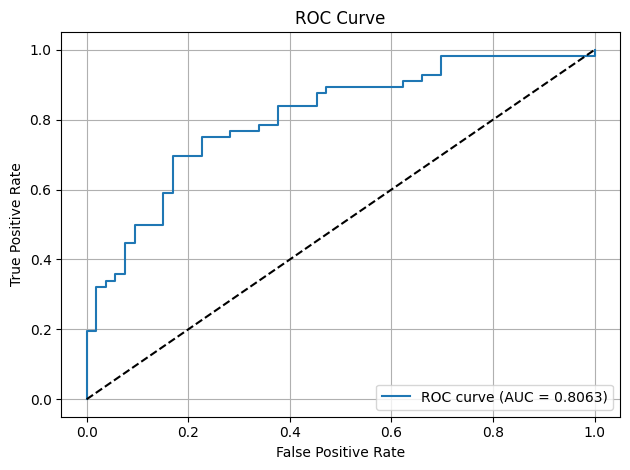

In [223]:
import numpy as np
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from scipy.special import softmax

# Convert to numpy arrays
logits = np.stack(lr_logits)             # shape (N, 2)
labels = np.array(lr_labels)             # shape (N,)

# Apply softmax to get probabilities
probs = softmax(logits, axis=1)       # shape (N, 2)
pos_probs = probs[:, 1]               # probability of class 1

# Compute ROC curve and AUC
fpr, tpr, _ = roc_curve(labels, pos_probs)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure()
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()